In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 读取数据集
df = pd.read_csv("AB_NYC_2019.csv")

In [3]:
print(df.shape)
df.head()
df.info()

(48895, 16)
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                    

In [4]:
# 数据清洗：去掉极端高价异常值，方便绘图
df = df[df["price"] < 500]
df = df.dropna(subset=["reviews_per_month"])

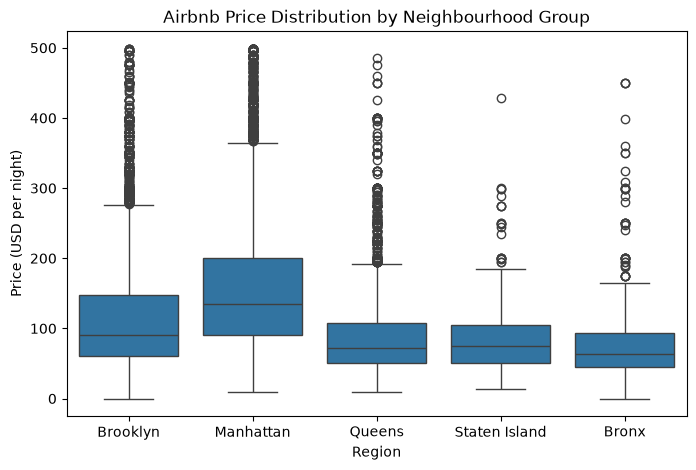

In [5]:
# 可视化1：不同行政区（neighbourhood_group）价格箱线图
plt.figure(figsize=(8,5))
sns.boxplot(x="neighbourhood_group", y="price", data=df)
plt.title("Airbnb Price Distribution by Neighbourhood Group")
plt.xlabel("Region")
plt.ylabel("Price (USD per night)")
plt.savefig("plot1_price_region.png")
plt.show()

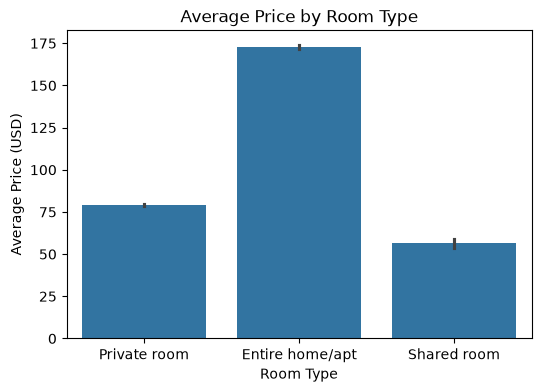

In [6]:
# 可视化2：房源房间类型与平均价格柱状图
plt.figure(figsize=(6,4))
sns.barplot(x="room_type", y="price", data=df)
plt.title("Average Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Price (USD)")
plt.savefig("plot2_price_roomtype.png")
plt.show()

In [7]:
# 简单统计结果
print(df.groupby("neighbourhood_group")["price"].mean())
print(df.groupby("room_type")["price"].mean())

neighbourhood_group
Bronx             77.570447
Brooklyn         112.009533
Manhattan        155.702117
Queens            90.639737
Staten Island     88.255591
Name: price, dtype: float64
room_type
Entire home/apt    172.704167
Private room        79.087792
Shared room         56.582143
Name: price, dtype: float64
